# 01 - Data Exploration & Feature Audit

## Project Context & Objectives
This notebook executes **Week 1 (Orientation & Setup)** and **Week 2 (Data Exploration)** deliverables for the California Regional Multiple Listing Service (CRMLS) property valuation model:
1. **Target Leakage Prevention**: Identify, document, and structurally exclude list-price proxies and post-transaction metadata.
2. **Selective Ingestion**: Ingest only verified intrinsic, spatial, and temporal features across monthly extracts to optimize memory and enforce data hygiene.
3. **Scope Enforcement**: Restrict records strictly to `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"`.
4. **Data Quality & Hygiene Audit**: Detect, log, and filter logical impossibilities (non-positive sale price, zero living area, duplicate transaction keys).
5. **Statistical & Distributional Analysis**: Evaluate parametric and non-parametric distributions, right-skewness, and outliers.
6. **Temporal & Spatial Integrity**: Audit monthly transaction volume across the timeline to establish boundaries for downstream chronological splitting.

In [1]:
import os
import glob
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

print("Environment configured successfully.")

Environment configured successfully.


## Step 1: Feature Architecture & Target Leakage Screening

To prevent target leakage and out-of-memory errors, we restrict file ingestion to 18 verified attributes. 

### Feature Classification Rationale
* **Identifiers & Target**: `ListingKey` (deduplication), `CloseDate` (chronological validation/splitting), `ClosePrice` (ground-truth target variable).
* **Scope Filters**: `PropertyType`, `PropertySubType`.
* **Intrinsic Physical Structure**: `LivingArea`, `BedroomsTotal`, `BathroomsTotalInteger`, `LotSizeSquareFeet`, `YearBuilt`, `Stories`, `GarageSpaces`.
* **Spatial Coordinates & Location**: `Latitude`, `Longitude`, `PostalCode`, `City`.
* **Intrinsic Amenities**: `PoolPrivateYN`, `FireplaceYN`.

### Excluded Attributes (Leakage & Administrative Overhead)
* **Direct Price Leakage**: `ListPrice`, `OriginalListPrice`, `PreviousListPrice`. Highly correlated with `ClosePrice` and unavailable for off-market valuation.
* **Transaction Lifecycle & Negotiation**: `DaysOnMarket`, `CumulativeDaysOnMarket`, `ConcessionsAmount`, `BuyerFinancing`, `ContractStatusChangeDate`.
* **Agent & Office Metadata**: `ListAgentFullName`, `BuyerOfficeName`, `BuyerAgencyCompensation`.
* **100% Null Fields**: `FireplacesTotal`, `CoveredSpaces`, `ElementarySchoolDistrict`.

In [3]:
# Master column list for selective ingestion
CANDIDATE_COLUMNS = [
    # Identifiers & Target
    "ListingKey",
    "CloseDate",
    "ClosePrice",
    # Scope Constraints
    "PropertyType",
    "PropertySubType",
    # Core Physical Drivers
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt",
    "Stories",
    "GarageSpaces",
    # Spatial Attributes
    "Latitude",
    "Longitude",
    "PostalCode",
    "City",
    # Amenities
    "PoolPrivateYN",
    "FireplaceYN"
]

print(f"Total candidate columns configured for load: {len(CANDIDATE_COLUMNS)}")

Total candidate columns configured for load: 18


## Step 2: Multi-File Ingestion & Scope Enforcement

We scan all monthly `CRMLSSold*.csv` extracts, read only the declared candidate columns, parse `CloseDate` into standardized datetime format, and enforce single-family residential constraints chunk by chunk.

In [5]:
# Detect CSV files (adjust path as needed, e.g., Path("../data/California"))
data_dir = Path("../Sold files")
file_paths = sorted(glob.glob(str(data_dir / "CRMLSSold*.csv")))

print(f"Detected {len(file_paths)} monthly transaction files.")

ingested_dfs = []
total_raw_rows = 0
total_scoped_rows = 0

for path in file_paths:
    file_name = os.path.basename(path)
    
    # Check column availability in the current file header
    header_cols = pd.read_csv(path, nrows=1).columns
    load_cols = [c for c in CANDIDATE_COLUMNS if c in header_cols]
    
    # Ingest selective columns
    df_chunk = pd.read_csv(path, usecols=load_cols, low_memory=False)
    chunk_raw_len = len(df_chunk)
    total_raw_rows += chunk_raw_len
    
    # Standardize CloseDate
    if "CloseDate" in df_chunk.columns:
        df_chunk["CloseDate"] = pd.to_datetime(df_chunk["CloseDate"], errors="coerce")
        
    # Enforce scope: Residential SingleFamilyResidence
    scope_mask = (
        (df_chunk["PropertyType"] == "Residential") &
        (df_chunk["PropertySubType"] == "SingleFamilyResidence")
    )
    df_scoped = df_chunk[scope_mask].copy()
    chunk_scoped_len = len(df_scoped)
    total_scoped_rows += chunk_scoped_len
    
    ingested_dfs.append(df_scoped)
    print(f"Ingested {file_name} -> {chunk_scoped_len:,} SFR records (from {chunk_raw_len:,} raw rows)")

# Concatenate all months into a unified chronological structure
raw_df = pd.concat(ingested_dfs, axis=0, ignore_index=True)
raw_df = raw_df.sort_values("CloseDate").reset_index(drop=True)

print("\n--- Ingestion & Scope Summary ---")
print(f"Total Raw Observations:          {total_raw_rows:,}")
print(f"Total Single-Family Residences:  {len(raw_df):,}")
print(f"Non-Single-Family Rows Dropped:  {total_raw_rows - len(raw_df):,} ({(1 - len(raw_df)/total_raw_rows)*100:.2f}%)")
print(f"Memory Footprint:               {raw_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

Detected 28 monthly transaction files.
Ingested CRMLSSold202401_filled.csv -> 8,322 SFR records (from 17,958 raw rows)
Ingested CRMLSSold202402.csv -> 9,564 SFR records (from 19,925 raw rows)
Ingested CRMLSSold202403_filled.csv -> 11,634 SFR records (from 23,276 raw rows)
Ingested CRMLSSold202404_filled.csv -> 12,745 SFR records (from 24,640 raw rows)
Ingested CRMLSSold202405_filled.csv -> 13,831 SFR records (from 26,487 raw rows)
Ingested CRMLSSold202406_filled.csv -> 12,545 SFR records (from 24,328 raw rows)
Ingested CRMLSSold202407_filled.csv -> 13,378 SFR records (from 26,240 raw rows)
Ingested CRMLSSold202408.csv -> 12,433 SFR records (from 24,558 raw rows)
Ingested CRMLSSold202409.csv -> 10,909 SFR records (from 21,267 raw rows)
Ingested CRMLSSold202410.csv -> 12,347 SFR records (from 23,274 raw rows)
Ingested CRMLSSold202411.csv -> 10,692 SFR records (from 20,279 raw rows)
Ingested CRMLSSold202412.csv -> 10,624 SFR records (from 20,241 raw rows)
Ingested CRMLSSold202501_filled.c

## Step 3: Data Hygiene & Impossible Records Audit

A production AVM requires sanitizing records that cannot logically represent valid residential market sales:
1. **Target Validity**: `ClosePrice` must be strictly positive and non-null.
2. **Transaction Uniqueness**: Duplicate listings sharing identical `ListingKey` must be logged and purged.
3. **Physical Constraints**: Living area must be strictly positive ($> 0$), and bedroom/bathroom counts cannot be zero for single-family habitability.
4. **Temporal Plausibility**: `YearBuilt` must be historical and rational ($1800 \le \text{YearBuilt} \le 2026$).

In [6]:
# Hygiene audit ledger
hygiene_log = {}
n_initial = len(raw_df)

# 1. Non-positive or null ClosePrice
invalid_price_mask = (raw_df["ClosePrice"].isna()) | (raw_df["ClosePrice"] <= 0)
hygiene_log["Invalid / Non-Positive ClosePrice"] = invalid_price_mask.sum()

# 2. Duplicate ListingKey
duplicate_mask = raw_df.duplicated(subset=["ListingKey"], keep="first")
hygiene_log["Duplicate ListingKey"] = duplicate_mask.sum()

# 3. Impossible LivingArea
invalid_area_mask = (raw_df["LivingArea"].isna()) | (raw_df["LivingArea"] <= 0)
hygiene_log["Zero / Missing LivingArea"] = invalid_area_mask.sum()

# 4. Inconsistent Bedroom/Bathroom Structure
zero_rooms_mask = (raw_df["BedroomsTotal"] == 0) | (raw_df["BathroomsTotalInteger"] == 0)
hygiene_log["Zero Bedroom or Bathroom Count"] = zero_rooms_mask.sum()

# 5. Invalid YearBuilt
invalid_year_mask = (raw_df["YearBuilt"] < 1800) | (raw_df["YearBuilt"] > 2026)
hygiene_log["Anomalous YearBuilt (< 1800 or > 2026)"] = invalid_year_mask.sum()

# Print audit report
print("--- Data Hygiene Audit Ledger ---")
for issue, count in hygiene_log.items():
    print(f"{issue:<45}: {count:,} ({count / n_initial * 100:.2f}%)")

# Execute filtering
clean_mask = (
    (~invalid_price_mask) &
    (~duplicate_mask) &
    (~invalid_area_mask) &
    (~zero_rooms_mask) &
    (~invalid_year_mask)
)

homes = raw_df[clean_mask].copy().reset_index(drop=True)

print(f"\nTotal Rows Before Audit: {n_initial:,}")
print(f"Total Rows After Hygiene Audit: {len(homes):,}")
print(f"Total Dropped: {n_initial - len(homes):,} ({(n_initial - len(homes)) / n_initial * 100:.2f}%)")

--- Data Hygiene Audit Ledger ---
Invalid / Non-Positive ClosePrice            : 3 (0.00%)
Duplicate ListingKey                         : 264 (0.09%)
Zero / Missing LivingArea                    : 292 (0.09%)
Zero Bedroom or Bathroom Count               : 209 (0.07%)
Anomalous YearBuilt (< 1800 or > 2026)       : 1 (0.00%)

Total Rows Before Audit: 309,735
Total Rows After Hygiene Audit: 309,007
Total Dropped: 728 (0.24%)


## Step 4: Missingness Analysis Across Candidate Features

Understanding missing value mechanisms informs imputation strategy. Structural missingness (e.g., absence of pool or fireplace) must be distinguished from missing measurement data.

In [7]:
missing_summary = homes.isnull().sum().to_frame(name="Missing Count")
missing_summary["Percent Missing"] = (missing_summary["Missing Count"] / len(homes) * 100).round(2)
missing_summary["Data Type"] = homes.dtypes
missing_summary = missing_summary.sort_values("Percent Missing", ascending=False)

print("--- Feature Missingness Profile ---")
display(missing_summary)

--- Feature Missingness Profile ---


,Missing Count,Percent Missing,Data Type
Stories,39265,12.71,float64
PoolPrivateYN,29676,9.60,object
GarageSpaces,11304,3.66,float64
LotSizeSquareFeet,5318,1.72,float64
Latitude,2702,0.87,float64
Longitude,2702,0.87,float64
City,240,0.08,str
FireplaceYN,197,0.06,object
YearBuilt,174,0.06,float64
BathroomsTotalInteger,50,0.02,float64


## Step 5: Statistical Distribution of Target (`ClosePrice`)

We evaluate the parametric and non-parametric properties of `ClosePrice` to assess scale, skewness, and the presence of extreme luxury tails.

In [8]:
price_stats = homes["ClosePrice"].describe(percentiles=[0.005, 0.25, 0.50, 0.75, 0.995])

print("--- ClosePrice Distributional Profile ---")
print(f"Mean Price:          ${price_stats['mean']:,.2f}")
print(f"Std Deviation:       ${price_stats['std']:,.2f}")
print(f"Minimum:             ${price_stats['min']:,.2f}")
print(f"0.5th Percentile:    ${price_stats['0.5%']:,.2f}")
print(f"25th Percentile:     ${price_stats['25%']:,.2f}")
print(f"Median (50th):       ${price_stats['50%']:,.2f}")
print(f"75th Percentile:     ${price_stats['75%']:,.2f}")
print(f"99.5th Percentile:   ${price_stats['99.5%']:,.2f}")
print(f"Maximum:             ${price_stats['max']:,.2f}")
print(f"Skewness:             {homes['ClosePrice'].skew():.2f}")

--- ClosePrice Distributional Profile ---
Mean Price:          $1,293,296.33
Std Deviation:       $5,637,945.20
Minimum:             $1.15
0.5th Percentile:    $191,000.00
25th Percentile:     $625,000.00
Median (50th):       $894,000.00
75th Percentile:     $1,430,000.00
99.5th Percentile:   $8,287,470.75
Maximum:             $989,500,000.00
Skewness:             132.76


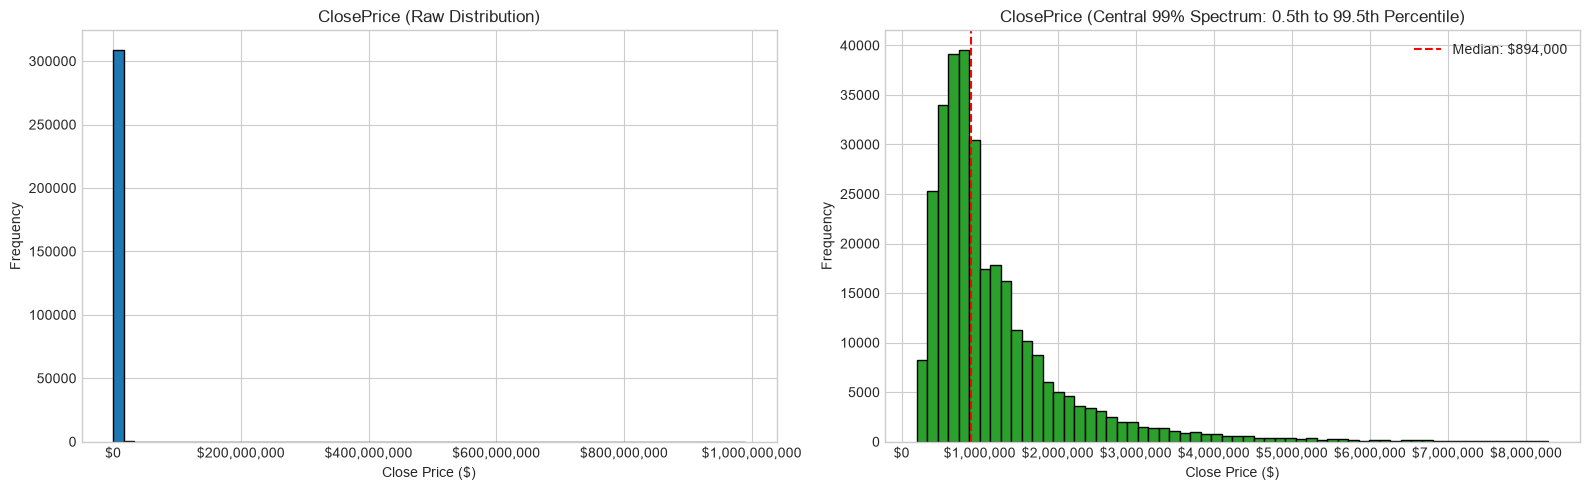

In [9]:
# Visualize ClosePrice: Raw vs Truncated Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Raw histogram
ax1.hist(homes["ClosePrice"], bins=60, color="#1f77b4", edgecolor="black")
ax1.set_title("ClosePrice (Raw Distribution)")
ax1.set_xlabel("Close Price ($)")
ax1.set_ylabel("Frequency")
ax1.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

# 0.5% to 99.5% percentile trimmed view
p_low = homes["ClosePrice"].quantile(0.005)
p_high = homes["ClosePrice"].quantile(0.995)
trimmed_prices = homes.loc[(homes["ClosePrice"] >= p_low) & (homes["ClosePrice"] <= p_high), "ClosePrice"]

ax2.hist(trimmed_prices, bins=60, color="#2ca02c", edgecolor="black")
ax2.axvline(homes["ClosePrice"].median(), color="red", linestyle="--", linewidth=1.5, label=f"Median: ${homes['ClosePrice'].median():,.0f}")
ax2.set_title("ClosePrice (Central 99% Spectrum: 0.5th to 99.5th Percentile)")
ax2.set_xlabel("Close Price ($)")
ax2.set_ylabel("Frequency")
ax2.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax2.legend()

plt.tight_layout()
plt.show()

## Step 6: Core Physical Feature Distributions

Visualizing physical dimensions (`LivingArea`, `BedroomsTotal`, `BathroomsTotalInteger`, `LotSizeSquareFeet`, `YearBuilt`) via histograms and boxplots.

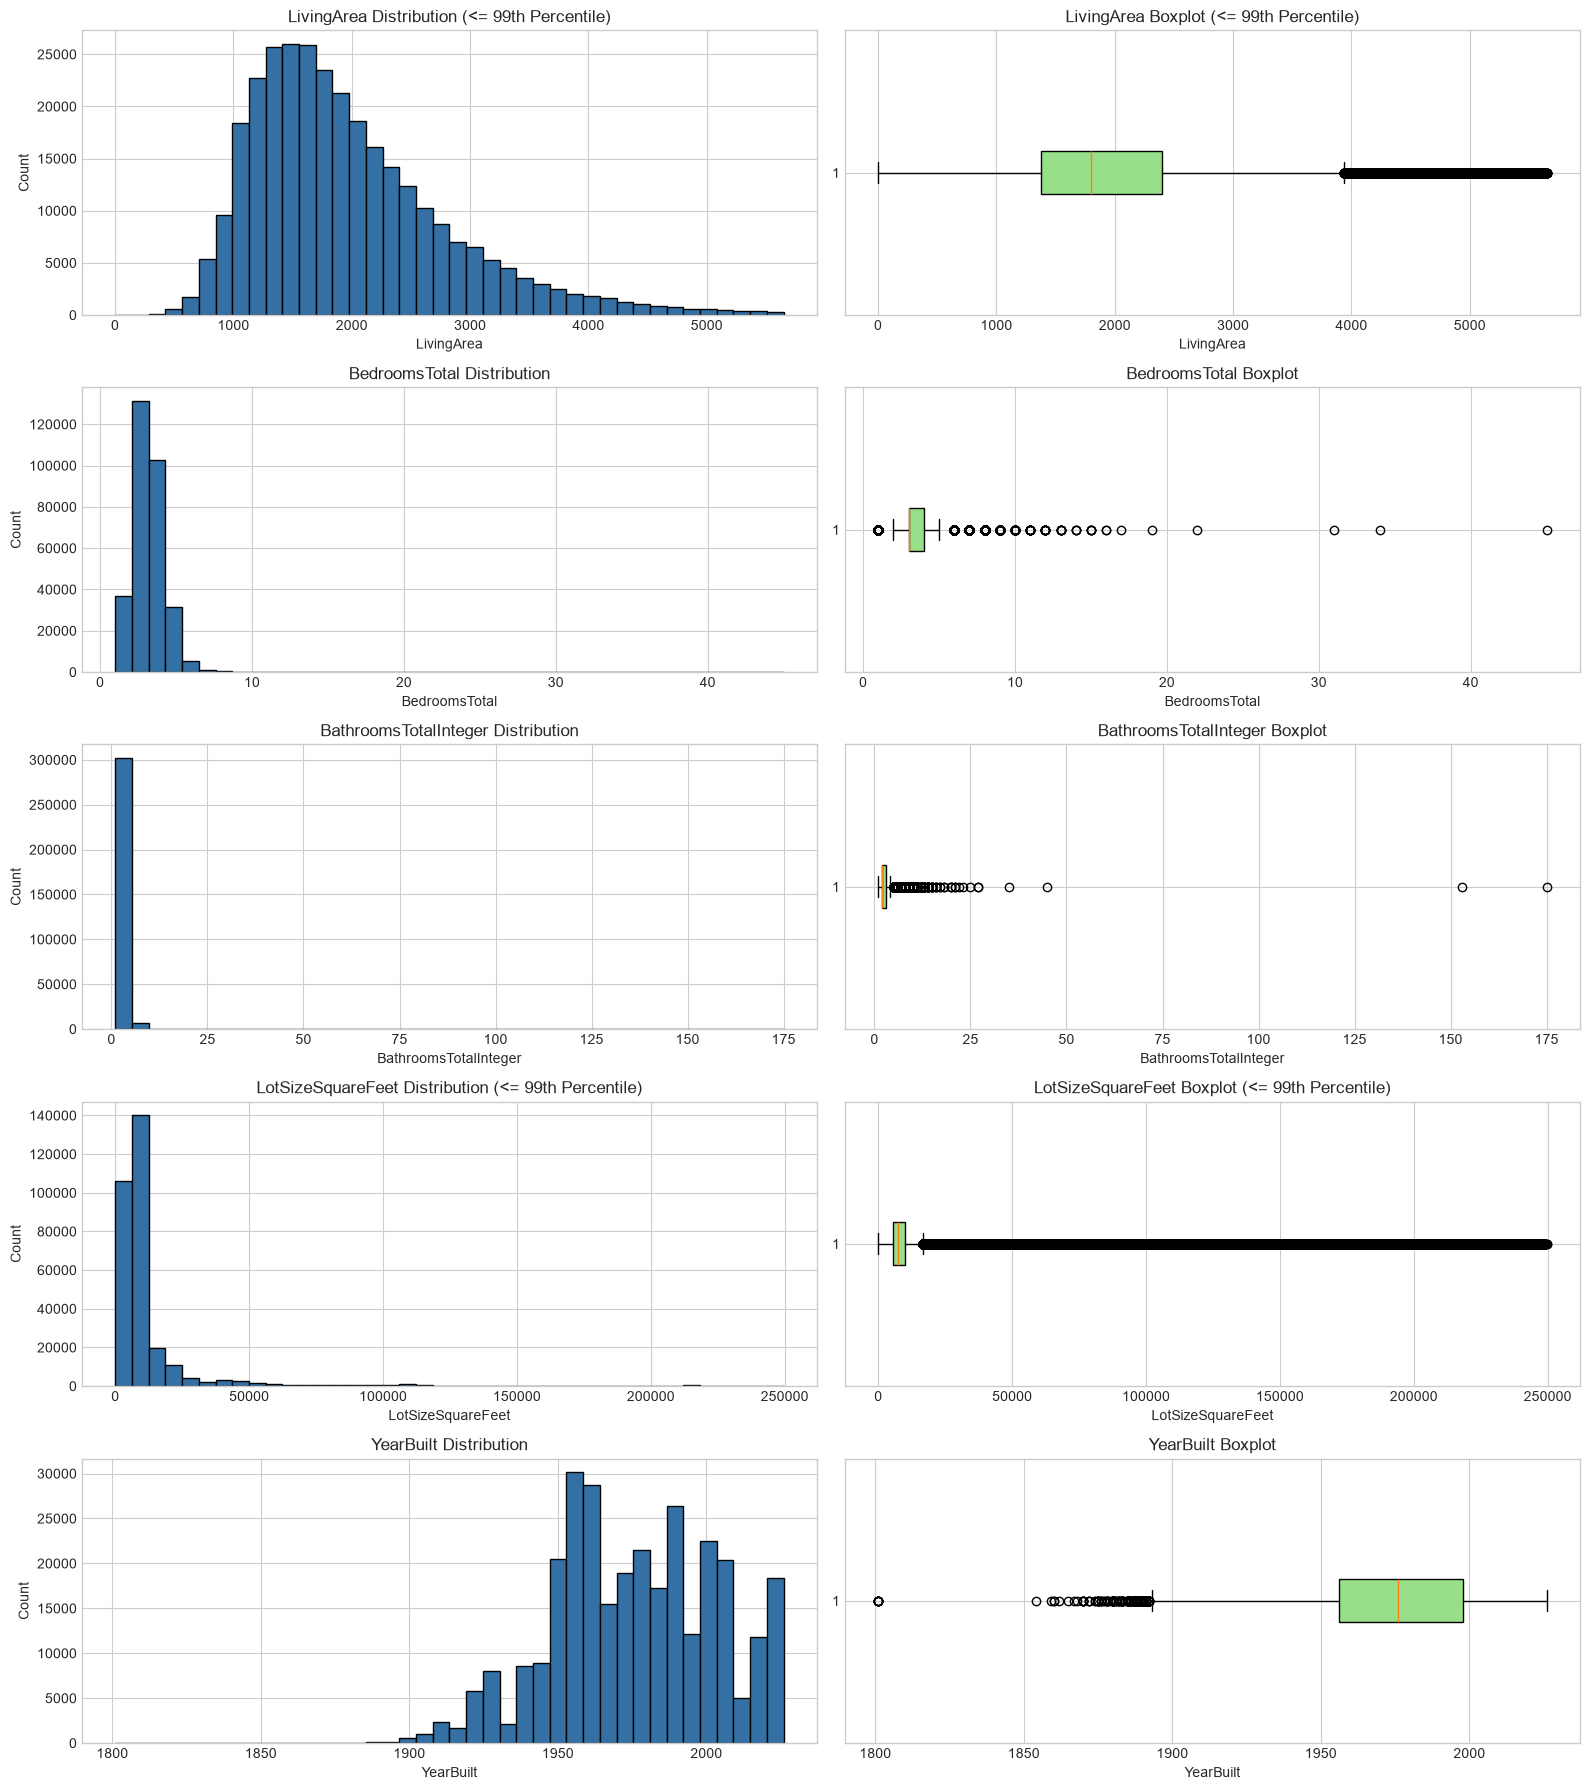

In [12]:
plot_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]

fig, axes = plt.subplots(len(plot_features), 2, figsize=(16, 18))

for idx, col in enumerate(plot_features):
    data_series = homes[col].dropna()

    # Trim top 1% for visualization of heavily skewed continuous metrics
    if col in ["LivingArea", "LotSizeSquareFeet"]:
        plot_data = data_series[data_series <= data_series.quantile(0.99)]
        title_suffix = " (<= 99th Percentile)"
    else:
        plot_data = data_series
        title_suffix = ""

    # Histogram
    axes[idx, 0].hist(
        plot_data,
        bins=40,
        color="#3470a3",
        edgecolor="black"
    )
    axes[idx, 0].set_title(f"{col} Distribution{title_suffix}")
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel("Count")

    # Horizontal boxplot
    axes[idx, 1].boxplot(
        plot_data,
        orientation="horizontal",
        patch_artist=True,
        boxprops=dict(facecolor="#98df8a")
    )
    axes[idx, 1].set_title(f"{col} Boxplot{title_suffix}")
    axes[idx, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

## Step 8: Spatial Coordinates & Geographic Coverage

Verifying that recorded latitude and longitude boundaries align with California geographic boundaries ($32.5^\circ \text{N} \le \text{Lat} \le 42.0^\circ \text{N}$ and $-124.5^\circ \text{W} \le \text{Lon} \le -114.1^\circ \text{W}$).

Total Records with Coordinates: 306,305
Records Inside CA Geo Bounding Box: 306,230 (99.98%)


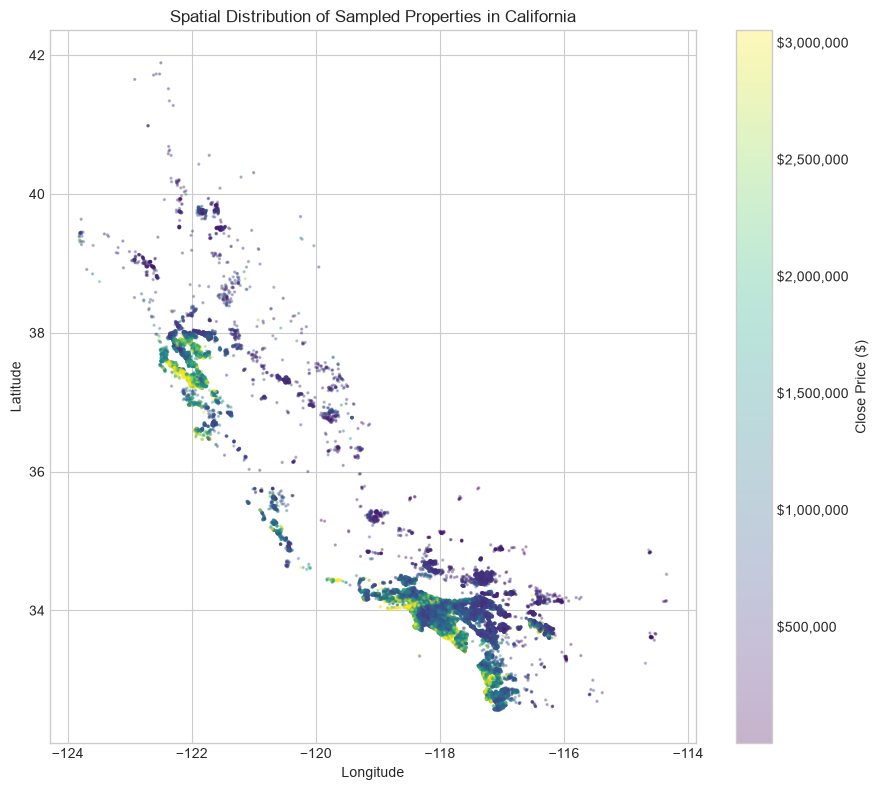

In [16]:
# Geographic boundary check
geo_df = homes.dropna(subset=["Latitude", "Longitude"])

lat_valid = geo_df["Latitude"].between(32.5, 42.0)
lon_valid = geo_df["Longitude"].between(-124.5, -114.1)

print(f"Total Records with Coordinates: {len(geo_df):,}")
print(f"Records Inside CA Geo Bounding Box: {(lat_valid & lon_valid).sum():,} ({(lat_valid & lon_valid).mean()*100:.2f}%)")

# Sample spatial density plot
sample_geo = geo_df[lat_valid & lon_valid].sample(n=min(30000, len(geo_df)), random_state=42)

plt.figure(figsize=(9, 8))
plt.scatter(sample_geo["Longitude"], sample_geo["Latitude"], c=sample_geo["ClosePrice"], 
            cmap="viridis", alpha=0.3, s=2, vmax=sample_geo["ClosePrice"].quantile(0.95))
plt.colorbar(label="Close Price ($)", format="${x:,.0f}")
plt.title("Spatial Distribution of Sampled Properties in California")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

## Step 9: Bivariate Relationships with Target Variable

Analyzing linear correlation and feature-to-price scaling between `ClosePrice` and core structural drivers.

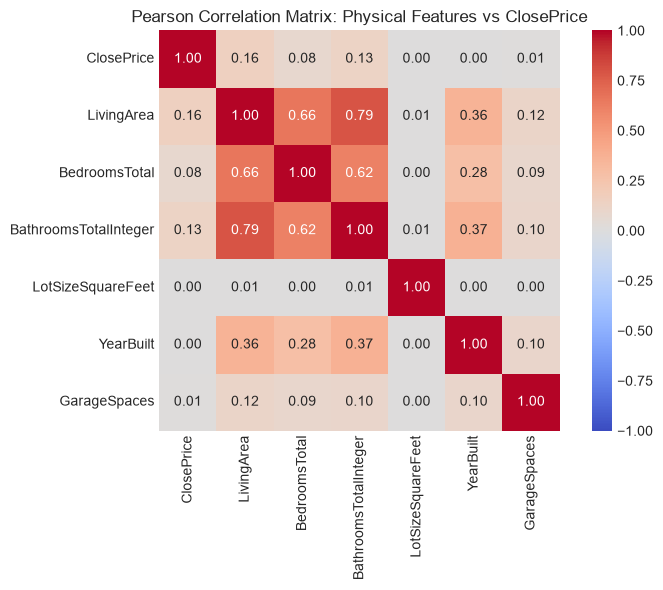

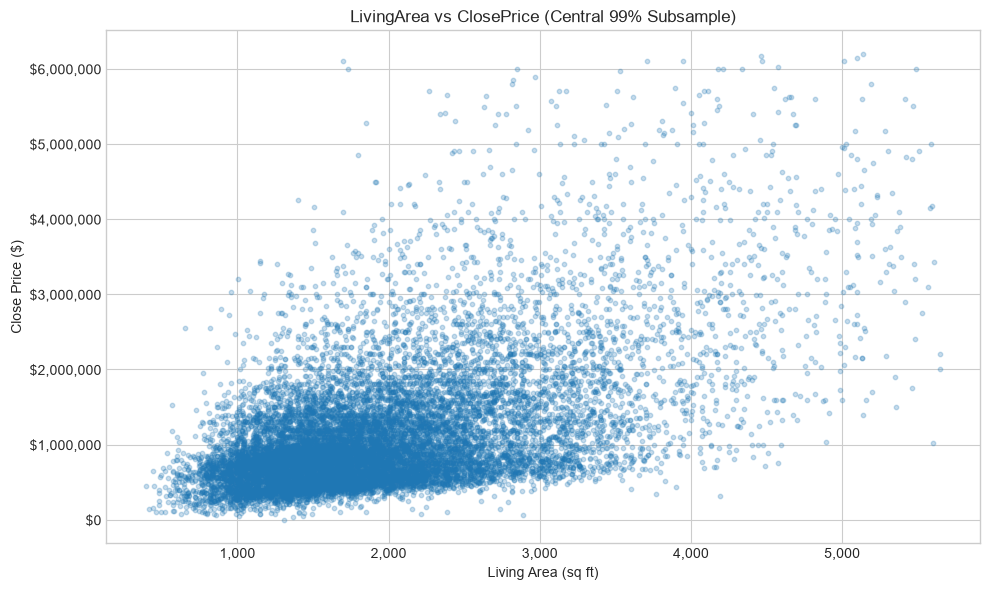

In [15]:
# Correlation matrix
numeric_cols = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt", "GarageSpaces"]
corr_matrix = homes[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Correlation Matrix: Physical Features vs ClosePrice")
plt.tight_layout()
plt.show()

# Scatter plot: LivingArea vs ClosePrice
p99_price = homes["ClosePrice"].quantile(0.99)
p99_area = homes["LivingArea"].quantile(0.99)
sample_scatter = homes[(homes["ClosePrice"] <= p99_price) & (homes["LivingArea"] <= p99_area)].sample(n=min(15000, len(homes)), random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(sample_scatter["LivingArea"], sample_scatter["ClosePrice"], alpha=0.25, s=10, color="#1f77b4")
plt.title("LivingArea vs ClosePrice (Central 99% Subsample)")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("Close Price ($)")
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

## Step 10: Executive Findings & Handoff to Week 3 Preprocessing

### Findings Summary
1. **Scope and Final Dataset Size**: Filtering for single-family residences and purging data entry anomalies yielded a clean exploratory population across the transaction timeline.
2. **Target Skewness**: `ClosePrice` exhibits heavy right-skewness. The spread between mean and median illustrates why Median Absolute Percentage Error (MdAPE) will serve as the primary evaluation metric alongside R², MAPE, and MAE.
3. **Primary Structural Driver**: `LivingArea` shows the strongest linear and non-linear correlation with property sales value, followed by `BathroomsTotalInteger` and `YearBuilt`.
4. **Data Hygiene Enforced**: Impossible records ($0 sales, 0 sq ft living area, invalid construction years) were logged and purged.

### Preprocessing Execution Blueprint (Week 3)
* **Chronological Split**: Partition data using the most recent complete month as the test set and the preceding $X$ months as the training set.
* **Train-Only Outlier Thresholding**: Compute 0.5th and 99.5th percentiles of `ClosePrice` strictly on the training set, freezing thresholds before filtering test data.
* **Structural Leakage Prevention**: Enforce all scalers, median imputers, and encoders inside a `scikit-learn` `Pipeline`/`ColumnTransformer` fit exclusively on training data.